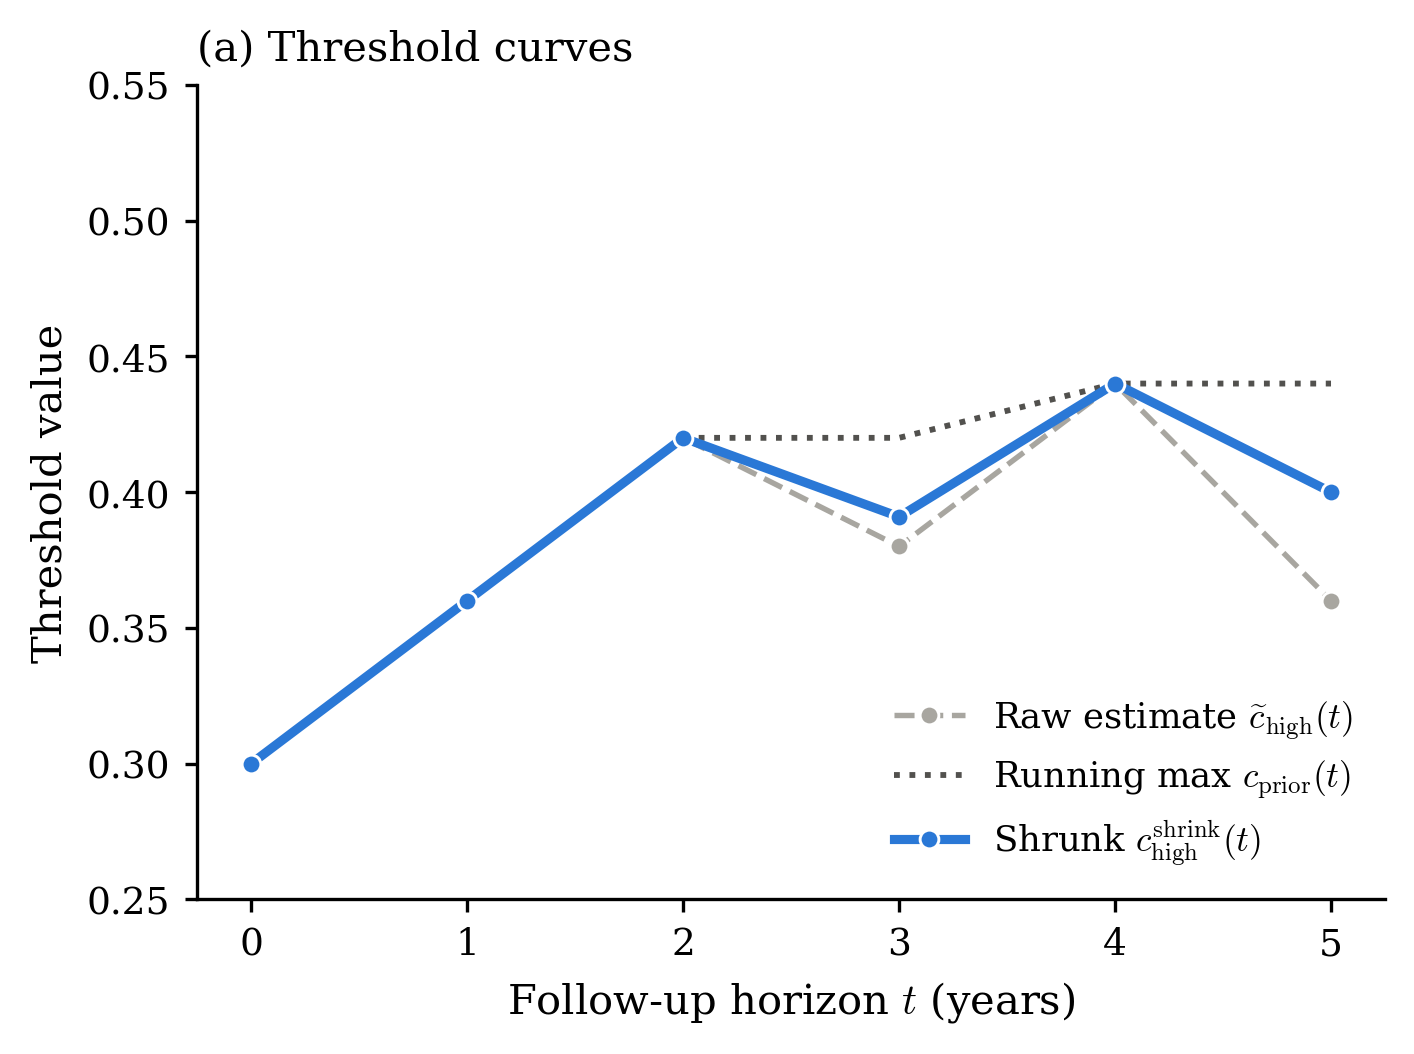

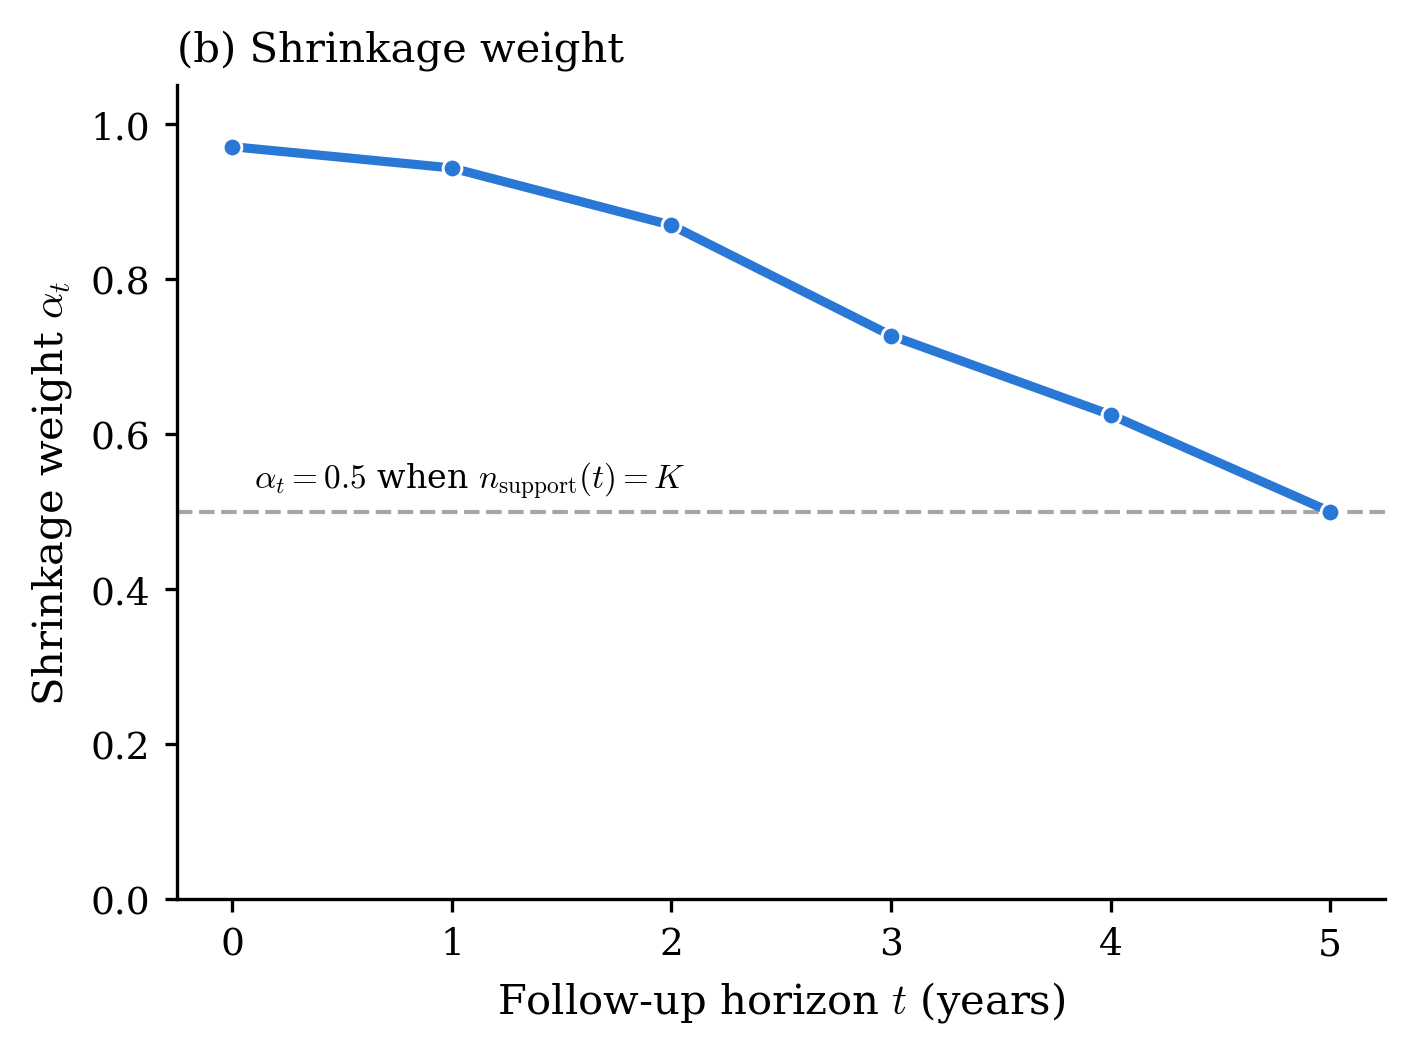

In [ ]:
"""
Illustrative figure for the stabilisation (empirical-Bayes shrinkage) step
in Section 1.4.3. Values below are SYNTHETIC, chosen only to demonstrate
the mechanism -- replace with your own training-set curves before using
this as a thesis figure, and update the caption accordingly if you do.

Saved as two separate files -- (a) and (b) -- so they can be placed as
individual subfigures in the thesis while keeping the "(a)"/"(b)" labels.
"""

import numpy as np
import matplotlib.pyplot as plt

# --- Style ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "axes.linewidth": 0.8,
    "figure.dpi": 300,
})

COLOR_MAIN = "#2a78d6"   # shrunk estimate (the star of the figure)
COLOR_RAW = "#a8a6a0"    # raw estimate (de-emphasised)
COLOR_PRIOR = "#52514e"  # running-max prior (de-emphasised)

# --- Synthetic data -----------------------------------------------------
t = np.array([0, 1, 2, 3, 4, 5])
n_support = np.array([100, 50, 20, 8, 5, 3])
K = 3

# Raw estimate tracks the running max while support is high, then dips
# twice -- a moderate one at t=3 and a larger one at t=5, where support
# has fallen to n_support=K=3 -- so the shrinkage effect is visible at
# more than one horizon instead of a single isolated point.
raw = np.array([0.30, 0.36, 0.42, 0.38, 0.44, 0.36])

prior = np.maximum.accumulate(raw)          # c_prior(t) = running max of raw
alpha = n_support / (n_support + K)         # alpha_t
shrunk = alpha * raw + (1 - alpha) * prior  # c_high^shrink(t)


def _style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")
    ax.tick_params(direction="out", length=3, colors="black")


# --- (a) threshold curves -------------------------------------------------
fig_a, ax = plt.subplots(figsize=(4.6, 3.4), constrained_layout=True)

ax.plot(t, raw, color=COLOR_RAW, linestyle="--", marker="o", markersize=4.5,
        markerfacecolor=COLOR_RAW, markeredgecolor="white", markeredgewidth=0.7,
        linewidth=1.3, zorder=2, label=r"Raw estimate $\widetilde{c}_{\mathrm{high}}(t)$")
ax.plot(t, prior, color=COLOR_PRIOR, linestyle=":", linewidth=1.4, zorder=2,
        label=r"Running max $c_{\mathrm{prior}}(t)$")
ax.plot(t, shrunk, color=COLOR_MAIN, marker="o", markersize=4.5,
        markerfacecolor=COLOR_MAIN, markeredgecolor="white", markeredgewidth=0.7,
        linewidth=2.2, zorder=3, label=r"Shrunk $c^{\mathrm{shrink}}_{\mathrm{high}}(t)$")

ax.set_xlabel("Follow-up horizon $t$ (years)")
ax.set_ylabel("Threshold value")
ax.set_xticks(t)
ax.set_ylim(0.25, 0.55)
ax.set_title("(a) Threshold curves", fontsize=10, loc="left")
ax.legend(frameon=False, loc="lower right")
_style_axis(ax)

fig_a.savefig("shrinkage_a.pdf")
fig_a.savefig("shrinkage_a.png", dpi=300)

# --- (b) shrinkage weight ---------------------------------------------
fig_b, ax = plt.subplots(figsize=(4.6, 3.4), constrained_layout=True)

ax.plot(t, alpha, color=COLOR_MAIN, marker="o", markersize=4.5,
        markerfacecolor=COLOR_MAIN, markeredgecolor="white", markeredgewidth=0.7,
        linewidth=2.2, zorder=3)
ax.axhline(0.5, color=COLOR_RAW, linestyle="--", linewidth=1.0, zorder=2)
ax.text(0.1, 0.53, r"$\alpha_t = 0.5$ when $n_{\mathrm{support}}(t) = K$",
        fontsize=8, color="black")
ax.set_xlabel("Follow-up horizon $t$ (years)")
ax.set_ylabel(r"Shrinkage weight $\alpha_t$")
ax.set_xticks(t)
ax.set_ylim(0, 1.05)
ax.set_title("(b) Shrinkage weight", fontsize=10, loc="left")
_style_axis(ax)

fig_b.savefig("shrinkage_b.pdf")
fig_b.savefig("shrinkage_b.png", dpi=300)